# Notebook 5 — Data Visualization

This notebook transforms the key findings from the exploratory and business analysis into clear, professional visualizations. The objective is to communicate important business performance patterns to managers, stakeholders, recruiters, and other non-technical audiences.

The analysis uses the cleaned retail sales dataset prepared in Notebook 2. The visualizations focus on business performance, branch and city performance, product performance, customer behavior, payment methods, employee performance, and time-based trends.

Each visualization is selected based on its ability to communicate a meaningful business insight and support better decision-making.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset created in Notebook 2
df = pd.read_csv("../data/processed/Kenya_Retail_Sales_Cleaned.csv")

# Display the first five records
df.head()


,Invoice_ID,Date,Time,Branch,City,Customer_ID,Customer_Type,Gender,Product_Category,Product,...,Cashier,Salesperson,Year,Month,Month Name,Quarter,Day,Day Name,Hour,Day Type
0,INV100000,2026-07-01,1900-01-01 16:41:00,Eldoret,Uasin Gishu,CUST3086,Member,Female,Electronics,Power Bank,...,Wanjiku,Grace,2026,7,July,3,1,Wednesday,16,Weekday
1,INV100001,2025-10-11,1900-01-01 15:11:00,Mombasa,Mombasa,CUST2099,Member,Male,Beverages,Tea,...,Mutua,Mercy,2025,10,October,4,11,Saturday,15,Weekend
2,INV100002,2025-04-24,1900-01-01 13:01:00,Kisumu,Kisumu,CUST7763,Member,Male,Groceries,Cooking Oil,...,Mutua,Brian,2025,4,April,2,24,Thursday,13,Weekday
3,INV100003,2026-02-13,1900-01-01 11:37:00,Kisumu,Kisumu,CUST1881,Normal,Female,Electronics,Power Bank,...,Wanjiku,John,2026,2,February,1,13,Friday,11,Weekday
4,INV100004,2026-08-30,1900-01-01 13:54:00,Nakuru,Nakuru,CUST8901,Normal,Male,Groceries,Milk,...,Wanjiku,Brian,2026,8,August,3,30,Sunday,13,Weekend


In [2]:
#Check dataset dimensions
df.shape

(50000, 29)

In [3]:
#check available columns in the dataset
df.columns.tolist()

['Invoice_ID',
 'Date',
 'Time',
 'Branch',
 'City',
 'Customer_ID',
 'Customer_Type',
 'Gender',
 'Product_Category',
 'Product',
 'Quantity',
 'Unit_Price',
 'Discount',
 'Tax',
 'Total_Sales',
 'Cost',
 'Profit',
 'Payment_Method',
 'Rating',
 'Cashier',
 'Salesperson',
 'Year',
 'Month',
 'Month Name',
 'Quarter',
 'Day',
 'Day Name',
 'Hour',
 'Day Type']

In [4]:
#Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 29 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Invoice_ID        50000 non-null  str    
 1   Date              50000 non-null  str    
 2   Time              50000 non-null  str    
 3   Branch            50000 non-null  str    
 4   City              50000 non-null  str    
 5   Customer_ID       50000 non-null  str    
 6   Customer_Type     50000 non-null  str    
 7   Gender            50000 non-null  str    
 8   Product_Category  50000 non-null  str    
 9   Product           50000 non-null  str    
 10  Quantity          50000 non-null  int64  
 11  Unit_Price        50000 non-null  float64
 12  Discount          50000 non-null  float64
 13  Tax               50000 non-null  float64
 14  Total_Sales       50000 non-null  float64
 15  Cost              50000 non-null  float64
 16  Profit            50000 non-null  float64
 17  Paym

In [5]:
# Section 2: Calculate the key business performance indicators

total_revenue = df["Total_Sales"].sum()
total_profit = df["Profit"].sum()
total_transactions = df["Invoice_ID"].nunique()
average_transaction_value = total_revenue / total_transactions
profit_margin = (total_profit / total_revenue) * 100

print(f"Total Revenue: KES {total_revenue:,.2f}")
print(f"Total Profit: KES {total_profit:,.2f}")
print(f"Total Transactions: {total_transactions:,}")
print(f"Average Transaction Value: KES {average_transaction_value:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")

Total Revenue: KES 741,046,306.09
Total Profit: KES 191,360,934.10
Total Transactions: 50,000
Average Transaction Value: KES 14,820.93
Profit Margin: 25.82%


In [6]:
# Create a summary DataFrame for the executive KPIs

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Profit",
        "Total Transactions",
        "Average Transaction Value",
        "Profit Margin"
    ],
    "Value": [
        total_revenue,
        total_profit,
        total_transactions,
        average_transaction_value,
        profit_margin
    ]
})

kpi_summary

,KPI,Value
0,Total Revenue,7.410463e+08
1,Total Profit,1.913609e+08
2,Total Transactions,5.000000e+04
3,Average Transaction Value,1.482093e+04
4,Profit Margin,2.582307e+01


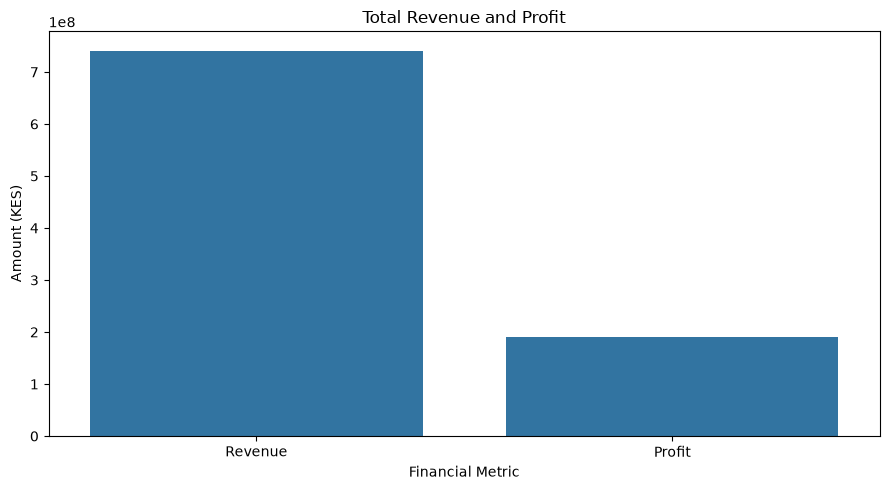

In [7]:
# Visualize the main financial KPIs

financial_kpis = pd.DataFrame({
    "Metric": ["Revenue", "Profit"],
    "Amount": [total_revenue, total_profit]
})

plt.figure(figsize=(9, 5))

sns.barplot(
    data=financial_kpis,
    x="Metric",
    y="Amount"
)

plt.title("Total Revenue and Profit")
plt.xlabel("Financial Metric")
plt.ylabel("Amount (KES)")
plt.tight_layout()
plt.show()

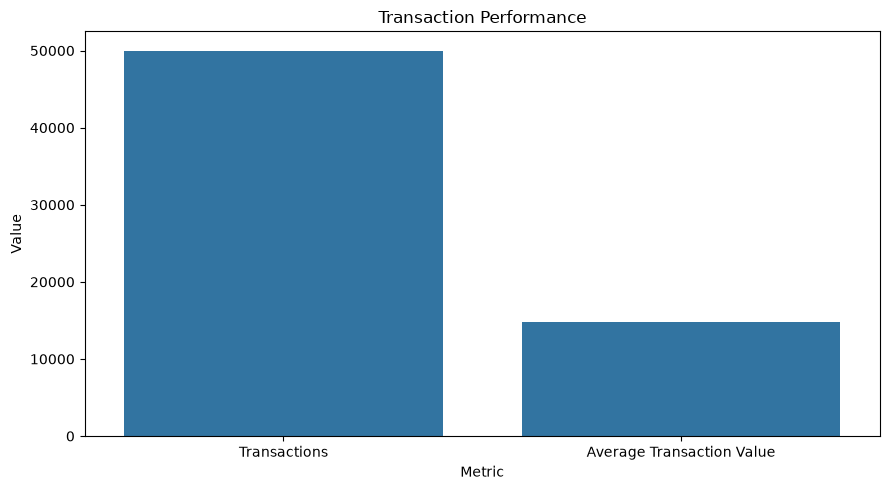

In [8]:
# Visualize transaction volume and average transaction value

transaction_kpis = pd.DataFrame({
    "Metric": ["Transactions", "Average Transaction Value"],
    "Value": [total_transactions, average_transaction_value]
})

fig, ax1 = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=transaction_kpis,
    x="Metric",
    y="Value",
    ax=ax1
)

ax1.set_title("Transaction Performance")
ax1.set_xlabel("Metric")
ax1.set_ylabel("Value")

plt.tight_layout()
plt.show()

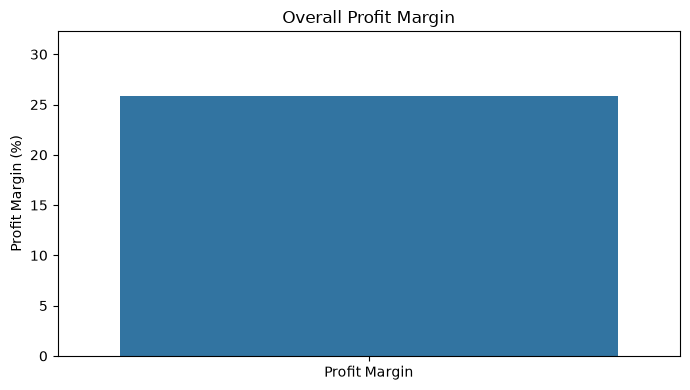

In [12]:
# Display the overall profit margin

plt.figure(figsize=(7, 4))

sns.barplot(
    x=["Profit Margin"],
    y=[profit_margin]
)

plt.title("Overall Profit Margin")
plt.xlabel("")
plt.ylabel("Profit Margin (%)")
plt.ylim(0, max(profit_margin * 1.25, 10))

plt.tight_layout()
plt.show()

In [13]:
# Section 3: Calculate branch performance metrics

branch_performance = df.groupby("Branch").agg(
    Revenue=("Total_Sales", "sum"),
    Profit=("Profit", "sum"),
    Transactions=("Invoice_ID", "nunique")
).reset_index()

branch_performance["Average Transaction Value"] = (
    branch_performance["Revenue"] / branch_performance["Transactions"]
)

branch_performance["Profit Margin (%)"] = (
    branch_performance["Profit"] / branch_performance["Revenue"]
) * 100

branch_performance.sort_values("Revenue", ascending=False)

,Branch,Revenue,Profit,Transactions,Average Transaction Value,Profit Margin (%)
5,Nakuru,1.069901e+08,27530326.44,7196,14868.001908,25.731648
3,Mombasa,1.069765e+08,27537270.80,7272,14710.740513,25.741419
0,Eldoret,1.064426e+08,27584451.30,7200,14783.691743,25.914865
6,Westlands,1.057603e+08,27290291.29,7015,15076.313766,25.803899
2,Migori,1.051070e+08,27311467.44,7012,14989.582289,25.984454
1,Kisumu,1.050057e+08,27265106.86,7192,14600.352266,25.965351
4,Nairobi CBD,1.047641e+08,26842019.97,7113,14728.532718,25.621403


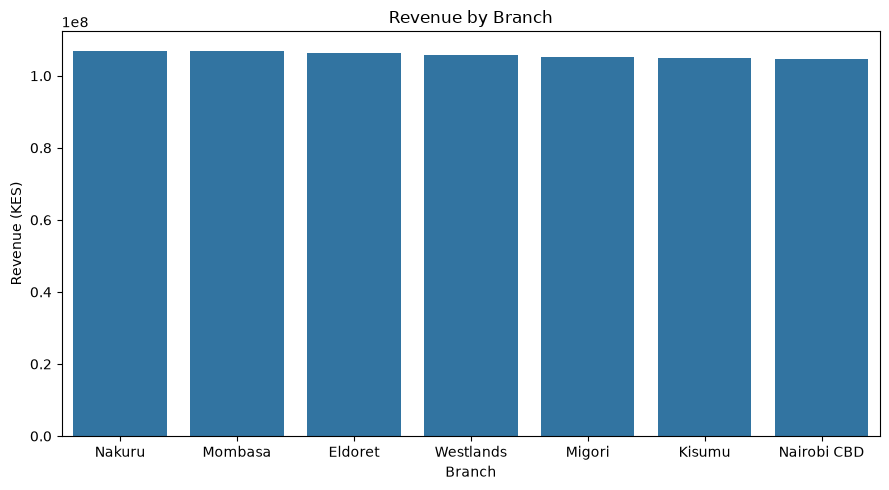

In [14]:
# Visualize revenue by branch

plt.figure(figsize=(9, 5))

sns.barplot(
    data=branch_performance.sort_values("Revenue", ascending=False),
    x="Branch",
    y="Revenue"
)

plt.title("Revenue by Branch")
plt.xlabel("Branch")
plt.ylabel("Revenue (KES)")
plt.tight_layout()
plt.show()

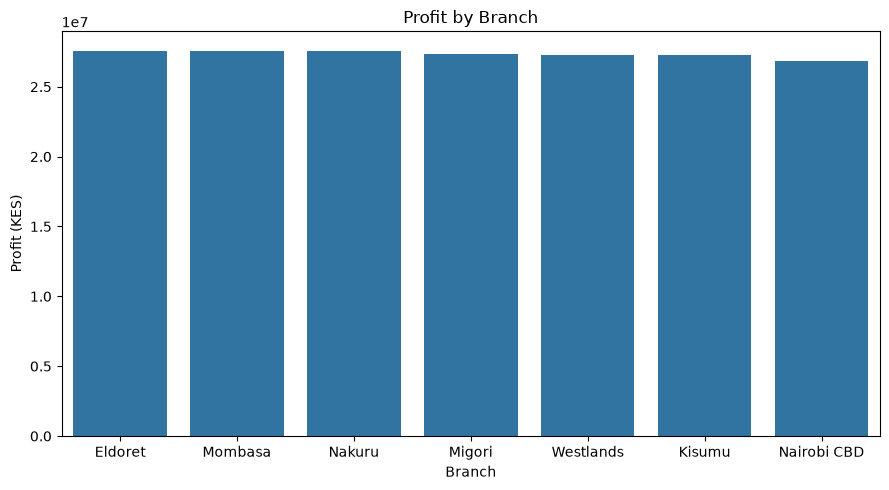

In [15]:
# Visualize profit by branch

plt.figure(figsize=(9, 5))

sns.barplot(
    data=branch_performance.sort_values("Profit", ascending=False),
    x="Branch",
    y="Profit"
)

plt.title("Profit by Branch")
plt.xlabel("Branch")
plt.ylabel("Profit (KES)")
plt.tight_layout()
plt.show()

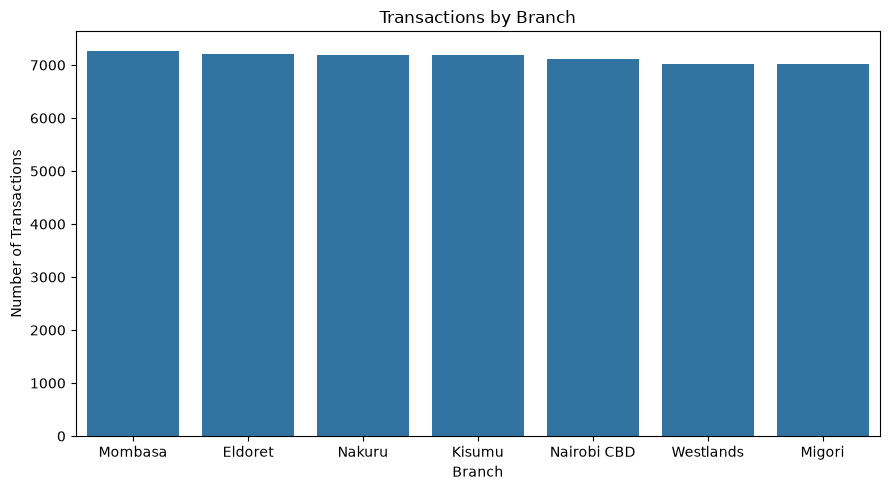

In [16]:
# Visualize transaction volume by branch

plt.figure(figsize=(9, 5))

sns.barplot(
    data=branch_performance.sort_values("Transactions", ascending=False),
    x="Branch",
    y="Transactions"
)

plt.title("Transactions by Branch")
plt.xlabel("Branch")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

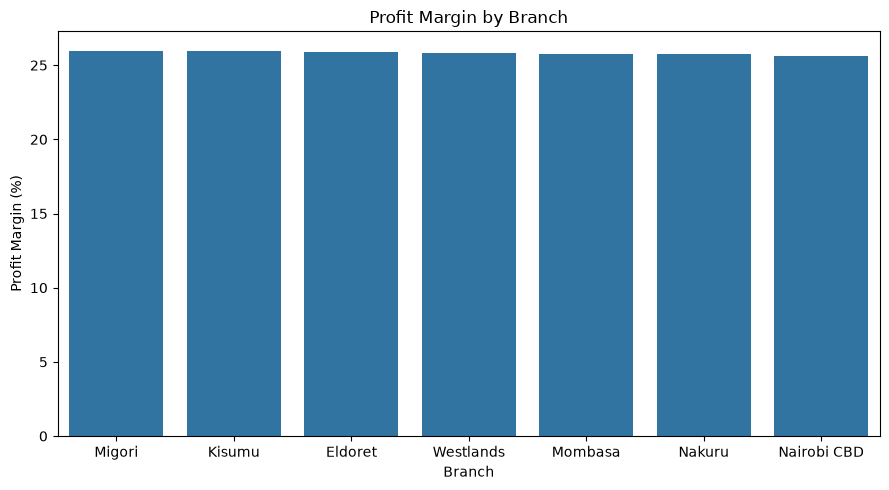

In [17]:
# Compare branch profit margins

plt.figure(figsize=(9, 5))

sns.barplot(
    data=branch_performance.sort_values("Profit Margin (%)", ascending=False),
    x="Branch",
    y="Profit Margin (%)"
)

plt.title("Profit Margin by Branch")
plt.xlabel("Branch")
plt.ylabel("Profit Margin (%)")
plt.tight_layout()
plt.show()

In [18]:
# Section 3: Calculate city performance metrics

city_performance = df.groupby("City").agg(
    Revenue=("Total_Sales", "sum"),
    Profit=("Profit", "sum"),
    Transactions=("Invoice_ID", "nunique")
).reset_index()

city_performance["Average Transaction Value"] = (
    city_performance["Revenue"] / city_performance["Transactions"]
)

city_performance["Profit Margin (%)"] = (
    city_performance["Profit"] / city_performance["Revenue"]
) * 100

city_performance.sort_values("Profit", ascending=False)

,City,Revenue,Profit,Transactions,Average Transaction Value,Profit Margin (%)
3,Nairobi,2.105244e+08,54132311.26,14128,14901.217036,25.713083
5,Uasin Gishu,1.064426e+08,27584451.30,7200,14783.691743,25.914865
2,Mombasa,1.069765e+08,27537270.80,7272,14710.740513,25.741419
4,Nakuru,1.069901e+08,27530326.44,7196,14868.001908,25.731648
1,Migori,1.051070e+08,27311467.44,7012,14989.582289,25.984454
0,Kisumu,1.050057e+08,27265106.86,7192,14600.352266,25.965351


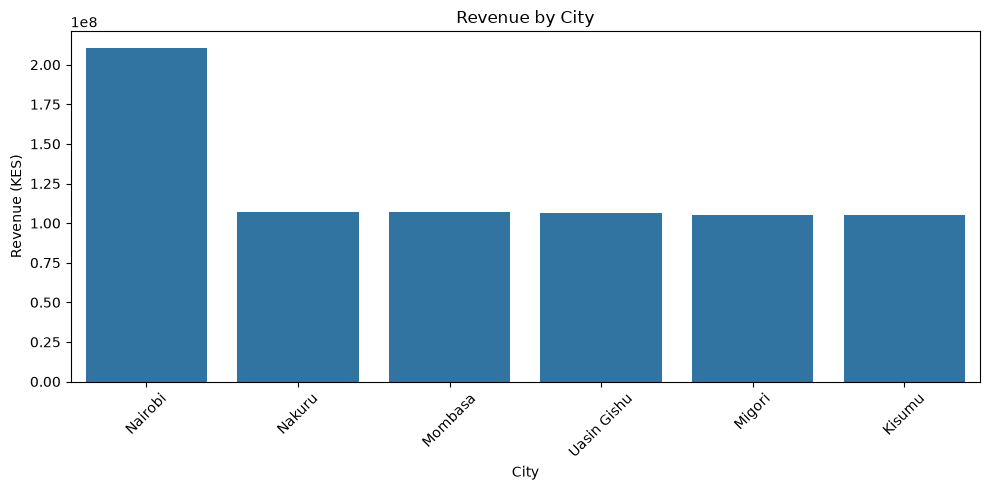

In [19]:
# Visualize revenue by city

plt.figure(figsize=(10, 5))

sns.barplot(
    data=city_performance.sort_values("Revenue", ascending=False),
    x="City",
    y="Revenue"
)

plt.title("Revenue by City")
plt.xlabel("City")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

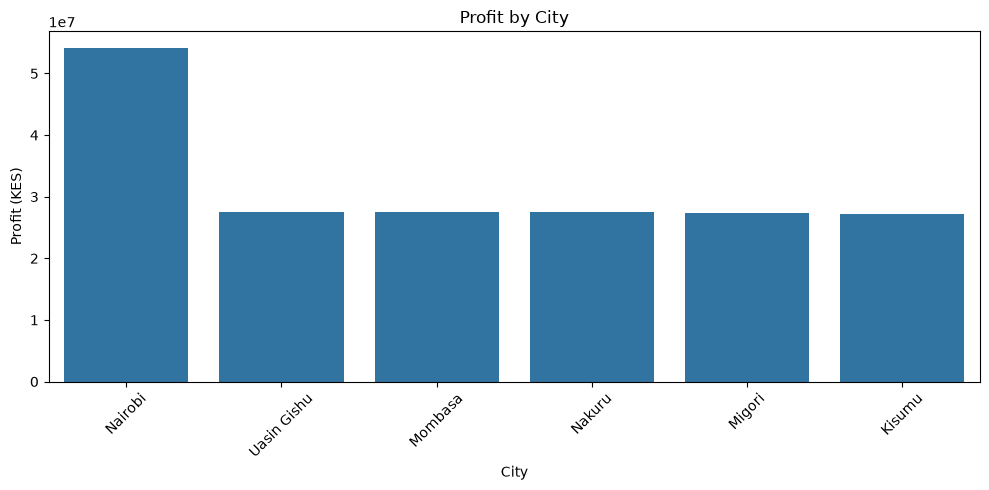

In [20]:
# Visualize profit by city

plt.figure(figsize=(10, 5))

sns.barplot(
    data=city_performance.sort_values("Profit", ascending=False),
    x="City",
    y="Profit"
)

plt.title("Profit by City")
plt.xlabel("City")
plt.ylabel("Profit (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

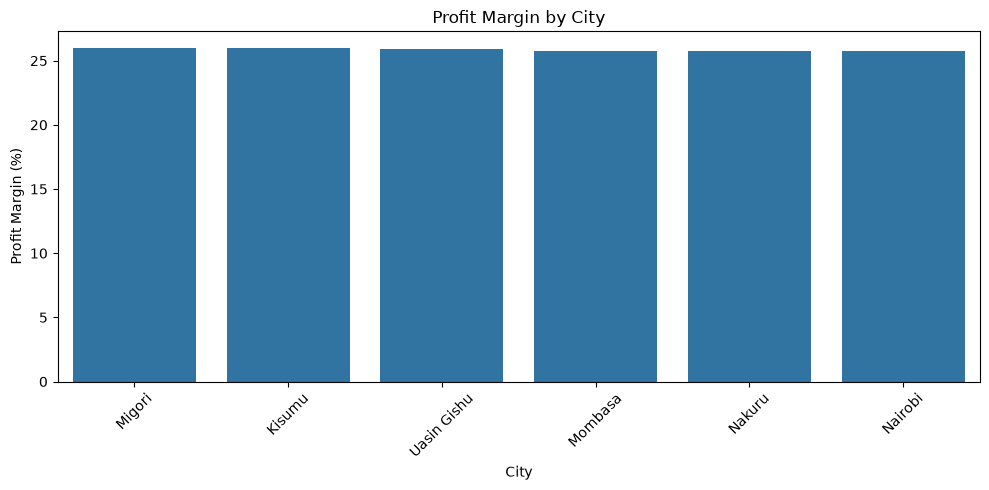

In [21]:
# Compare city profit margins

plt.figure(figsize=(10, 5))

sns.barplot(
    data=city_performance.sort_values("Profit Margin (%)", ascending=False),
    x="City",
    y="Profit Margin (%)"
)

plt.title("Profit Margin by City")
plt.xlabel("City")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
# Identify the highest-performing branch and city

highest_revenue_branch = branch_performance.loc[
    branch_performance["Revenue"].idxmax(), "Branch"
]

highest_profit_branch = branch_performance.loc[
    branch_performance["Profit"].idxmax(), "Branch"
]

highest_revenue_city = city_performance.loc[
    city_performance["Revenue"].idxmax(), "City"
]

highest_profit_city = city_performance.loc[
    city_performance["Profit"].idxmax(), "City"
]

print(f"Highest Revenue Branch: {highest_revenue_branch}")
print(f"Highest Profit Branch: {highest_profit_branch}")
print(f"Highest Revenue City: {highest_revenue_city}")
print(f"Highest Profit City: {highest_profit_city}")

Highest Revenue Branch: Nakuru
Highest Profit Branch: Eldoret
Highest Revenue City: Nairobi
Highest Profit City: Nairobi


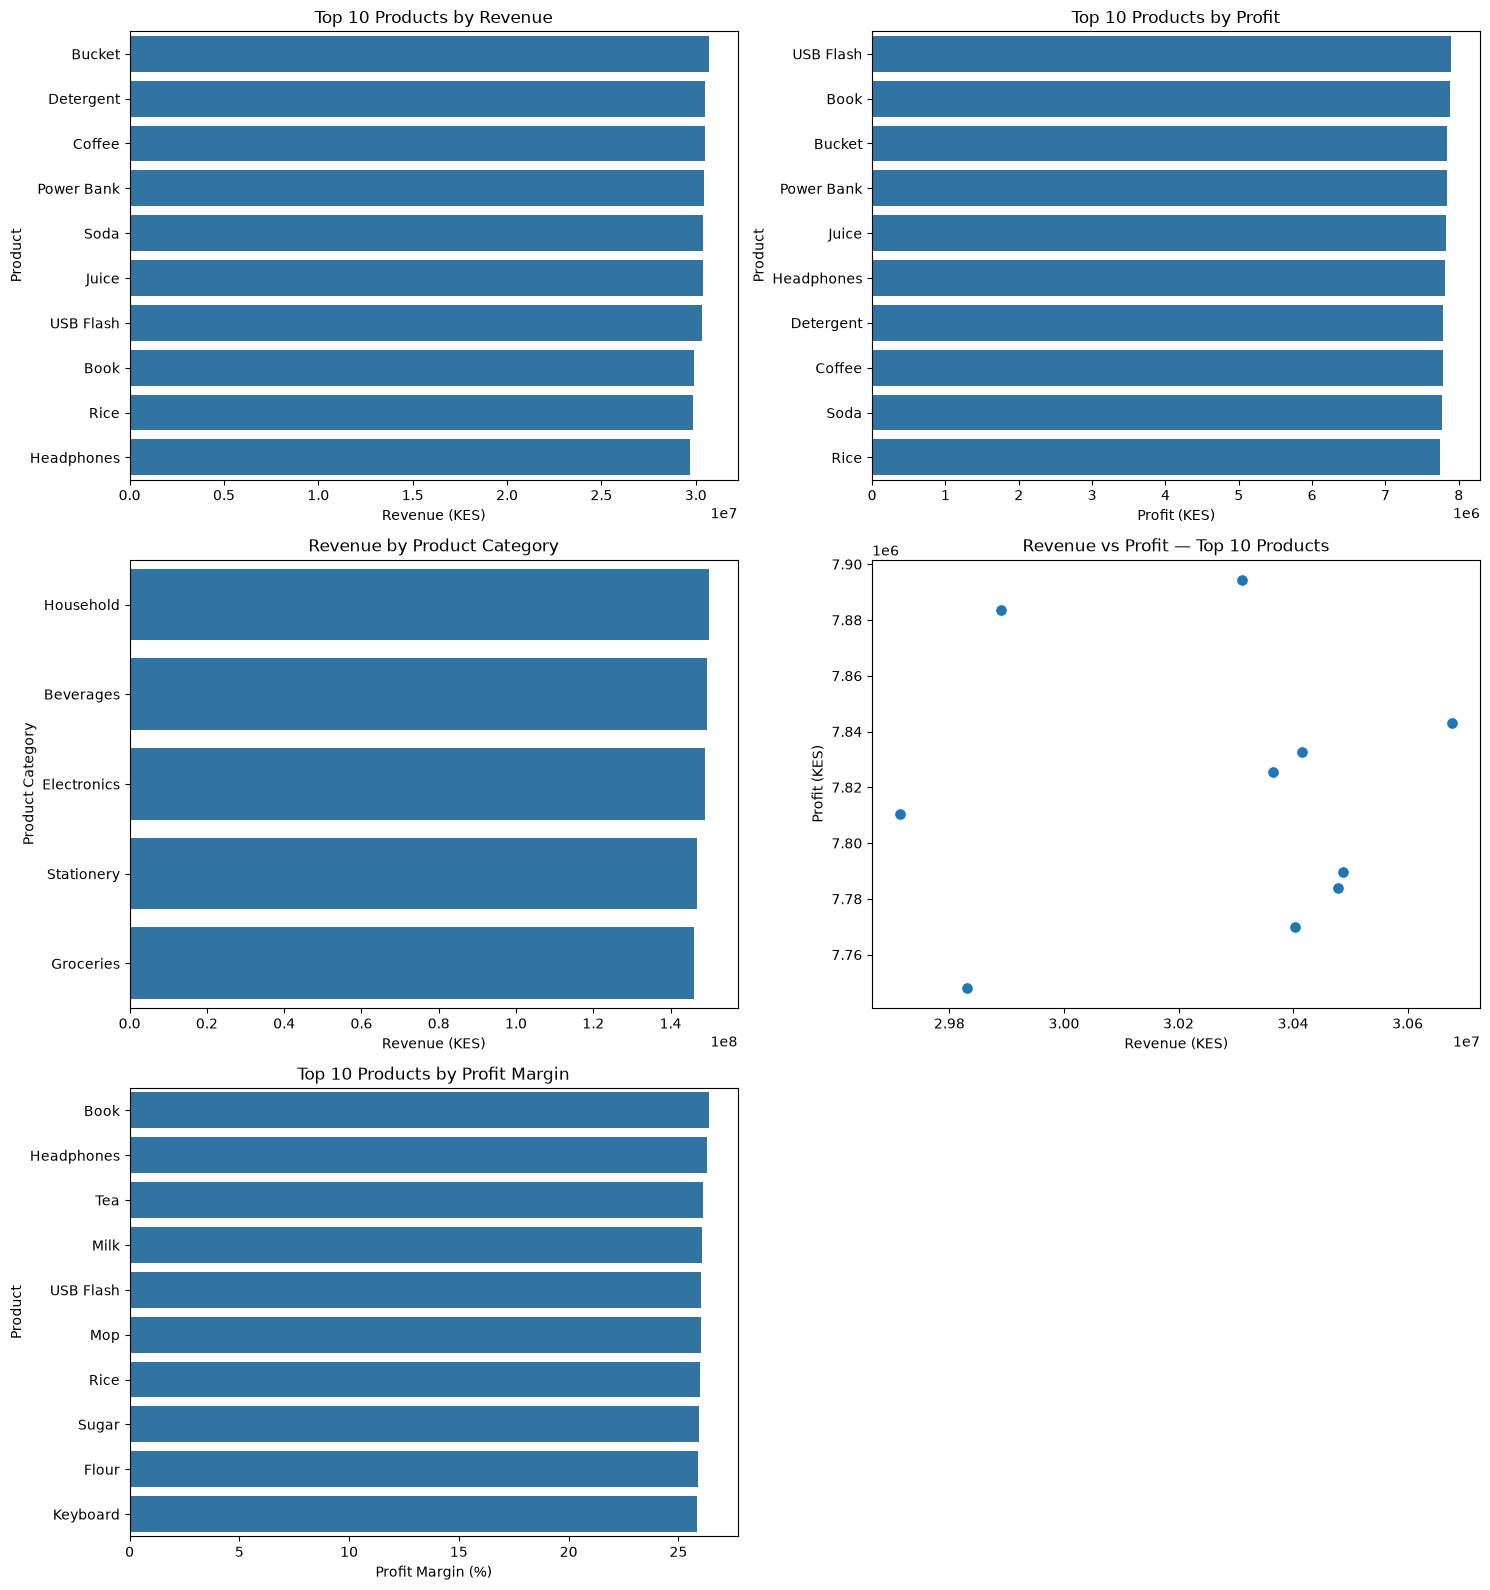

In [24]:
# Section 4: Product Performance Analysis

# Calculate product performance metrics
product_performance = df.groupby("Product").agg(
    Revenue=("Total_Sales", "sum"),
    Profit=("Profit", "sum"),
    Quantity_Sold=("Quantity", "sum"),
    Transactions=("Invoice_ID", "nunique")
).reset_index()

product_performance["Profit Margin (%)"] = (
    product_performance["Profit"] / product_performance["Revenue"]
) * 100


# Prepare data for the five visualizations
top_10_revenue = product_performance.sort_values(
    "Revenue", ascending=False
).head(10)

top_10_profit = product_performance.sort_values(
    "Profit", ascending=False
).head(10)

category_performance = df.groupby("Product_Category").agg(
    Revenue=("Total_Sales", "sum"),
    Profit=("Profit", "sum"),
    Quantity_Sold=("Quantity", "sum")
).reset_index()

top_10_products = product_performance.sort_values(
    "Revenue", ascending=False
).head(10)

top_10_margin = product_performance.sort_values(
    "Profit Margin (%)", ascending=False
).head(10)


# Create a 3-row, 2-column layout for the five charts
fig, axes = plt.subplots(3, 2, figsize=(15, 16))

# Chart 1: Top 10 Products by Revenue
sns.barplot(
    data=top_10_revenue,
    x="Revenue",
    y="Product",
    ax=axes[0, 0]
)

axes[0, 0].set_title("Top 10 Products by Revenue")
axes[0, 0].set_xlabel("Revenue (KES)")
axes[0, 0].set_ylabel("Product")


# Chart 2: Top 10 Products by Profit
sns.barplot(
    data=top_10_profit,
    x="Profit",
    y="Product",
    ax=axes[0, 1]
)

axes[0, 1].set_title("Top 10 Products by Profit")
axes[0, 1].set_xlabel("Profit (KES)")
axes[0, 1].set_ylabel("Product")


# Chart 3: Revenue by Product Category
sns.barplot(
    data=category_performance.sort_values(
        "Revenue", ascending=False
    ),
    x="Revenue",
    y="Product_Category",
    ax=axes[1, 0]
)

axes[1, 0].set_title("Revenue by Product Category")
axes[1, 0].set_xlabel("Revenue (KES)")
axes[1, 0].set_ylabel("Product Category")


# Chart 4: Revenue vs Profit
sns.scatterplot(
    data=top_10_products,
    x="Revenue",
    y="Profit",
    s=70,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Revenue vs Profit — Top 10 Products")
axes[1, 1].set_xlabel("Revenue (KES)")
axes[1, 1].set_ylabel("Profit (KES)")


# Chart 5: Top 10 Products by Profit Margin
sns.barplot(
    data=top_10_margin,
    x="Profit Margin (%)",
    y="Product",
    ax=axes[2, 0]
)

axes[2, 0].set_title("Top 10 Products by Profit Margin")
axes[2, 0].set_xlabel("Profit Margin (%)")
axes[2, 0].set_ylabel("Product")


# Remove the unused sixth subplot
axes[2, 1].axis("off")


# Adjust spacing between charts
plt.tight_layout()

plt.show()

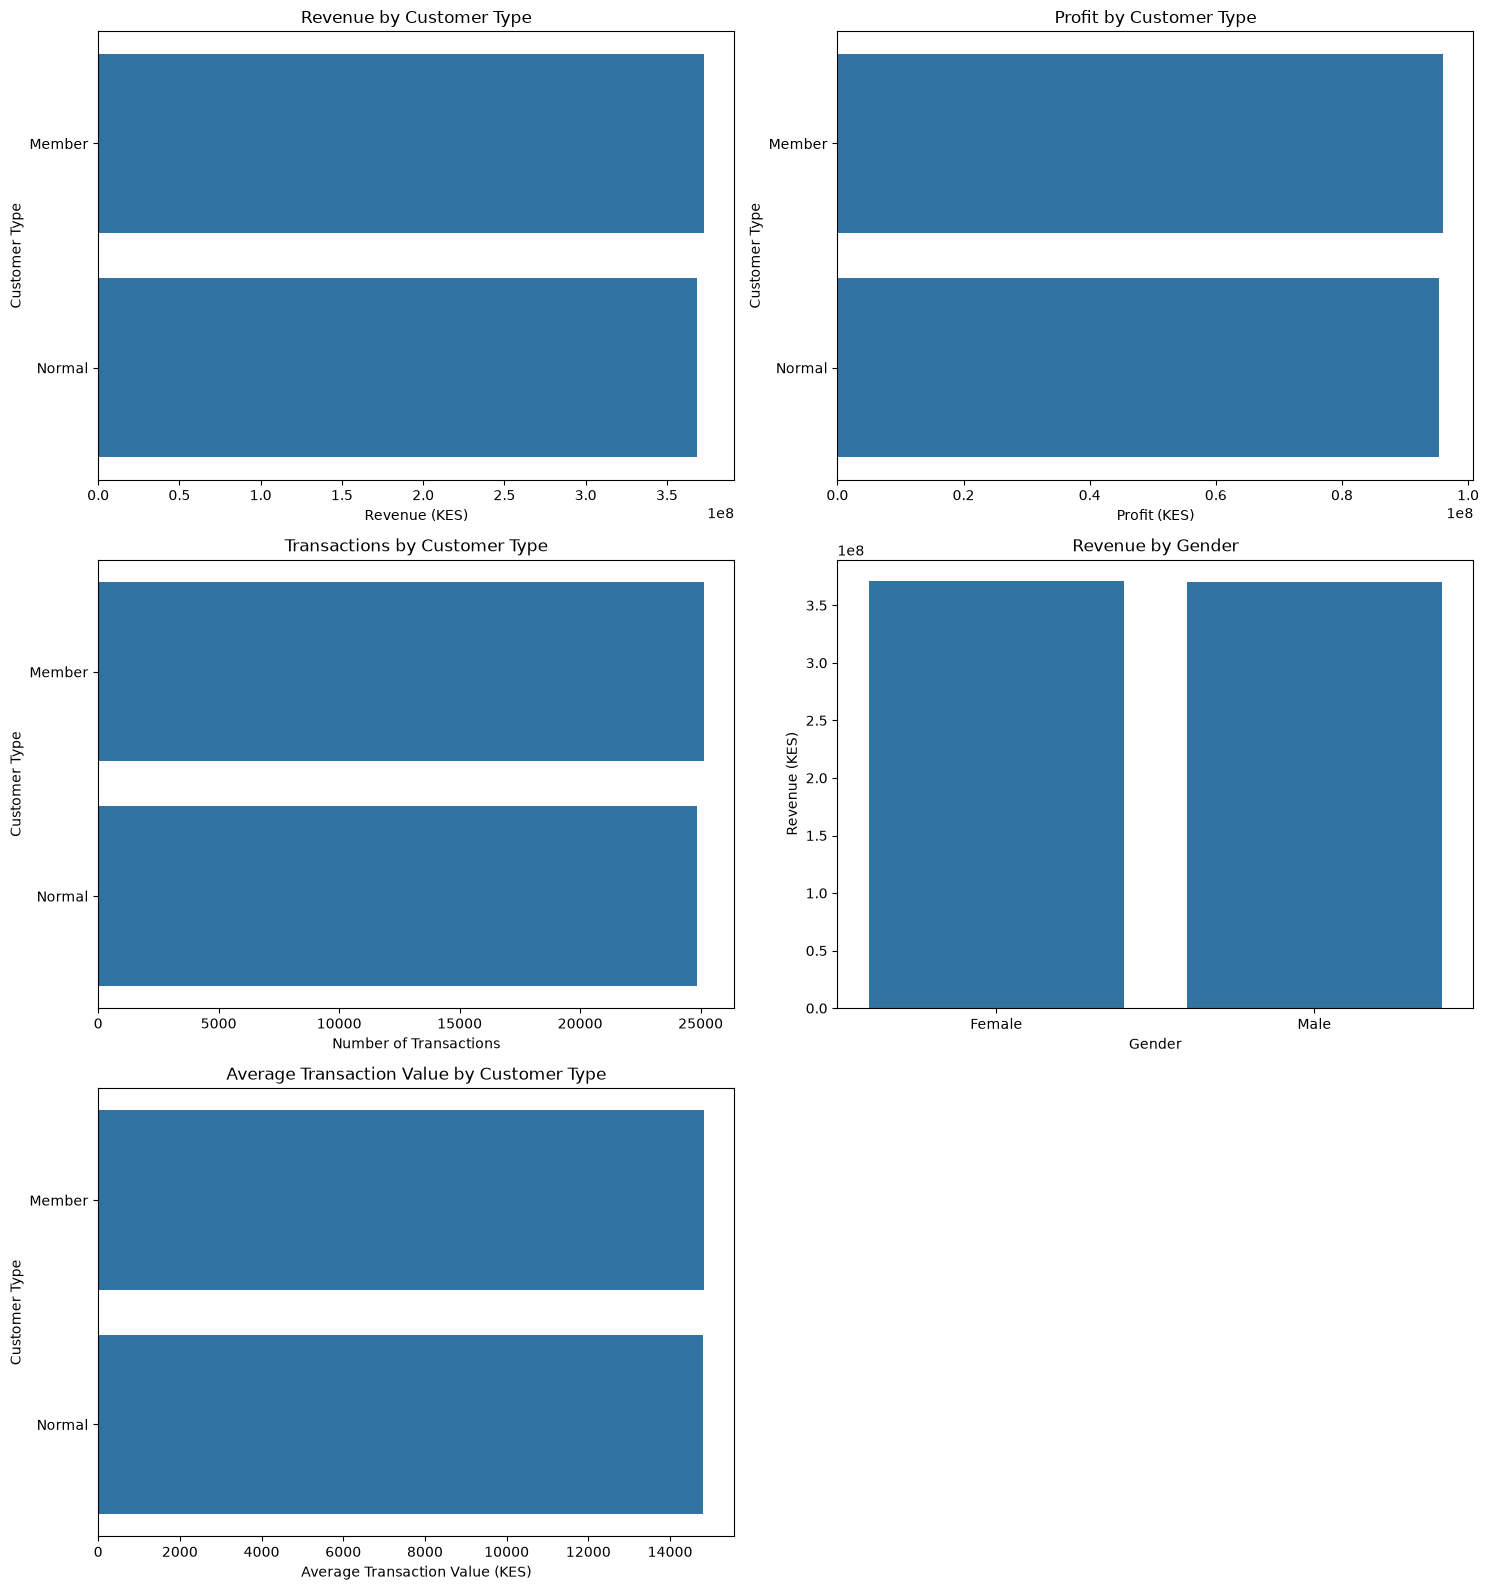

In [25]:
# Section 5: Customer Analysis

# Calculate customer performance metrics
customer_performance = df.groupby("Customer_Type").agg(
    Revenue=("Total_Sales", "sum"),
    Profit=("Profit", "sum"),
    Transactions=("Invoice_ID", "nunique"),
    Quantity_Sold=("Quantity", "sum")
).reset_index()

customer_performance["Average Transaction Value"] = (
    customer_performance["Revenue"] /
    customer_performance["Transactions"]
)

customer_performance["Profit Margin (%)"] = (
    customer_performance["Profit"] /
    customer_performance["Revenue"]
) * 100


# Calculate gender performance
gender_performance = df.groupby("Gender").agg(
    Revenue=("Total_Sales", "sum"),
    Profit=("Profit", "sum"),
    Transactions=("Invoice_ID", "nunique")
).reset_index()


# Create a 3-row, 2-column layout
fig, axes = plt.subplots(3, 2, figsize=(15, 16))


# Chart 1: Revenue by Customer Type
sns.barplot(
    data=customer_performance.sort_values("Revenue", ascending=False),
    x="Revenue",
    y="Customer_Type",
    ax=axes[0, 0]
)

axes[0, 0].set_title("Revenue by Customer Type")
axes[0, 0].set_xlabel("Revenue (KES)")
axes[0, 0].set_ylabel("Customer Type")


# Chart 2: Profit by Customer Type
sns.barplot(
    data=customer_performance.sort_values("Profit", ascending=False),
    x="Profit",
    y="Customer_Type",
    ax=axes[0, 1]
)

axes[0, 1].set_title("Profit by Customer Type")
axes[0, 1].set_xlabel("Profit (KES)")
axes[0, 1].set_ylabel("Customer Type")


# Chart 3: Transactions by Customer Type
sns.barplot(
    data=customer_performance.sort_values("Transactions", ascending=False),
    x="Transactions",
    y="Customer_Type",
    ax=axes[1, 0]
)

axes[1, 0].set_title("Transactions by Customer Type")
axes[1, 0].set_xlabel("Number of Transactions")
axes[1, 0].set_ylabel("Customer Type")


# Chart 4: Revenue by Gender
sns.barplot(
    data=gender_performance.sort_values("Revenue", ascending=False),
    x="Gender",
    y="Revenue",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Revenue by Gender")
axes[1, 1].set_xlabel("Gender")
axes[1, 1].set_ylabel("Revenue (KES)")


# Chart 5: Average Transaction Value by Customer Type
sns.barplot(
    data=customer_performance.sort_values(
        "Average Transaction Value",
        ascending=False
    ),
    x="Average Transaction Value",
    y="Customer_Type",
    ax=axes[2, 0]
)

axes[2, 0].set_title("Average Transaction Value by Customer Type")
axes[2, 0].set_xlabel("Average Transaction Value (KES)")
axes[2, 0].set_ylabel("Customer Type")


# Remove unused subplot
axes[2, 1].axis("off")


# Adjust spacing
plt.tight_layout()

plt.show()

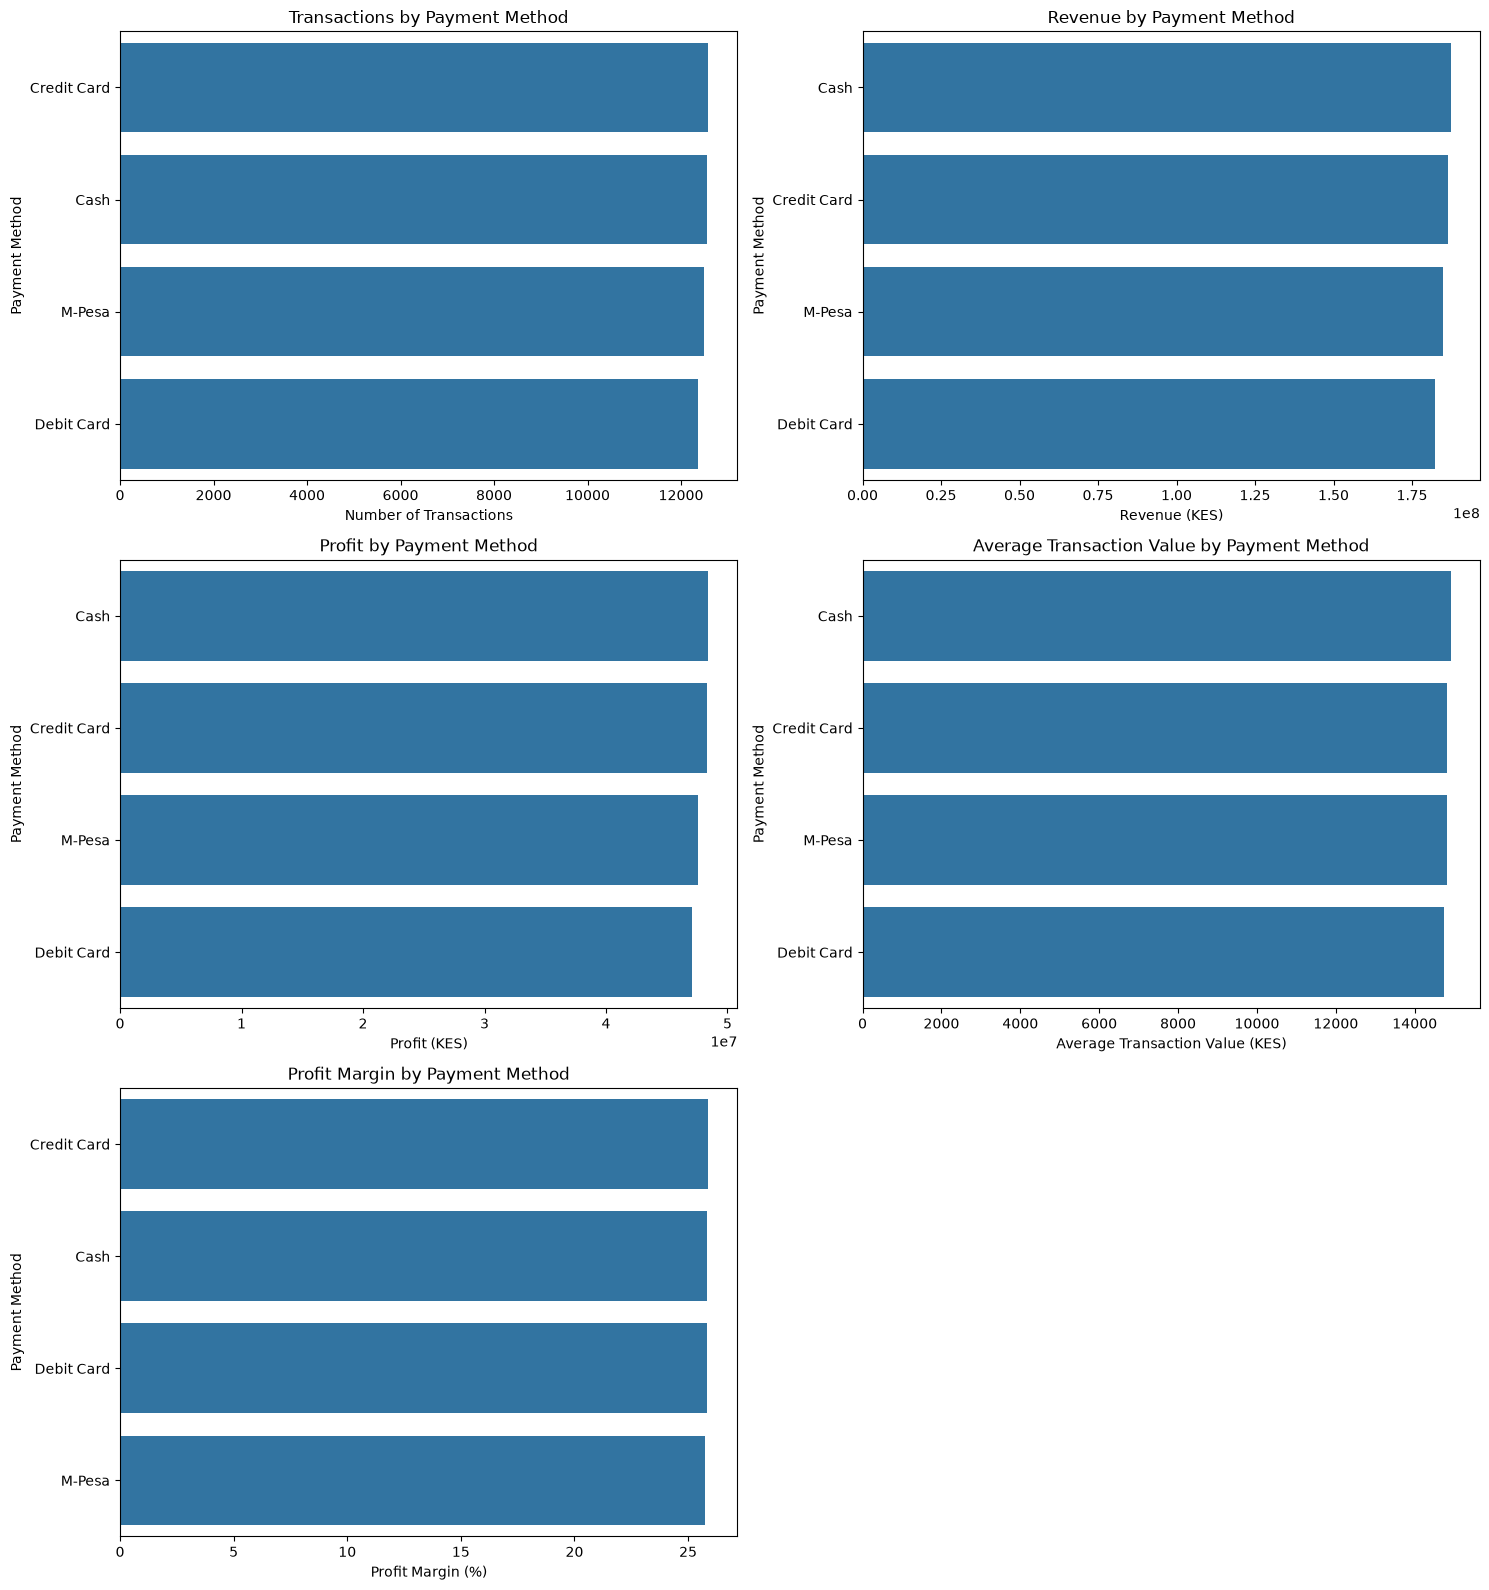

In [26]:
# Section 6: Payment Method Analysis

# Calculate payment method performance metrics
payment_performance = df.groupby("Payment_Method").agg(
    Transactions=("Invoice_ID", "nunique"),
    Revenue=("Total_Sales", "sum"),
    Profit=("Profit", "sum")
).reset_index()

payment_performance["Average Transaction Value"] = (
    payment_performance["Revenue"] /
    payment_performance["Transactions"]
)

payment_performance["Profit Margin (%)"] = (
    payment_performance["Profit"] /
    payment_performance["Revenue"]
) * 100


# Create a 3-row, 2-column layout
fig, axes = plt.subplots(3, 2, figsize=(15, 16))


# Chart 1: Transactions by Payment Method
sns.barplot(
    data=payment_performance.sort_values(
        "Transactions", ascending=False
    ),
    x="Transactions",
    y="Payment_Method",
    ax=axes[0, 0]
)

axes[0, 0].set_title("Transactions by Payment Method")
axes[0, 0].set_xlabel("Number of Transactions")
axes[0, 0].set_ylabel("Payment Method")


# Chart 2: Revenue by Payment Method
sns.barplot(
    data=payment_performance.sort_values(
        "Revenue", ascending=False
    ),
    x="Revenue",
    y="Payment_Method",
    ax=axes[0, 1]
)

axes[0, 1].set_title("Revenue by Payment Method")
axes[0, 1].set_xlabel("Revenue (KES)")
axes[0, 1].set_ylabel("Payment Method")


# Chart 3: Profit by Payment Method
sns.barplot(
    data=payment_performance.sort_values(
        "Profit", ascending=False
    ),
    x="Profit",
    y="Payment_Method",
    ax=axes[1, 0]
)

axes[1, 0].set_title("Profit by Payment Method")
axes[1, 0].set_xlabel("Profit (KES)")
axes[1, 0].set_ylabel("Payment Method")


# Chart 4: Average Transaction Value by Payment Method
sns.barplot(
    data=payment_performance.sort_values(
        "Average Transaction Value",
        ascending=False
    ),
    x="Average Transaction Value",
    y="Payment_Method",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Average Transaction Value by Payment Method")
axes[1, 1].set_xlabel("Average Transaction Value (KES)")
axes[1, 1].set_ylabel("Payment Method")


# Chart 5: Profit Margin by Payment Method
sns.barplot(
    data=payment_performance.sort_values(
        "Profit Margin (%)",
        ascending=False
    ),
    x="Profit Margin (%)",
    y="Payment_Method",
    ax=axes[2, 0]
)

axes[2, 0].set_title("Profit Margin by Payment Method")
axes[2, 0].set_xlabel("Profit Margin (%)")
axes[2, 0].set_ylabel("Payment Method")


# Remove unused subplot
axes[2, 1].axis("off")


# Adjust spacing
plt.tight_layout()

plt.show()

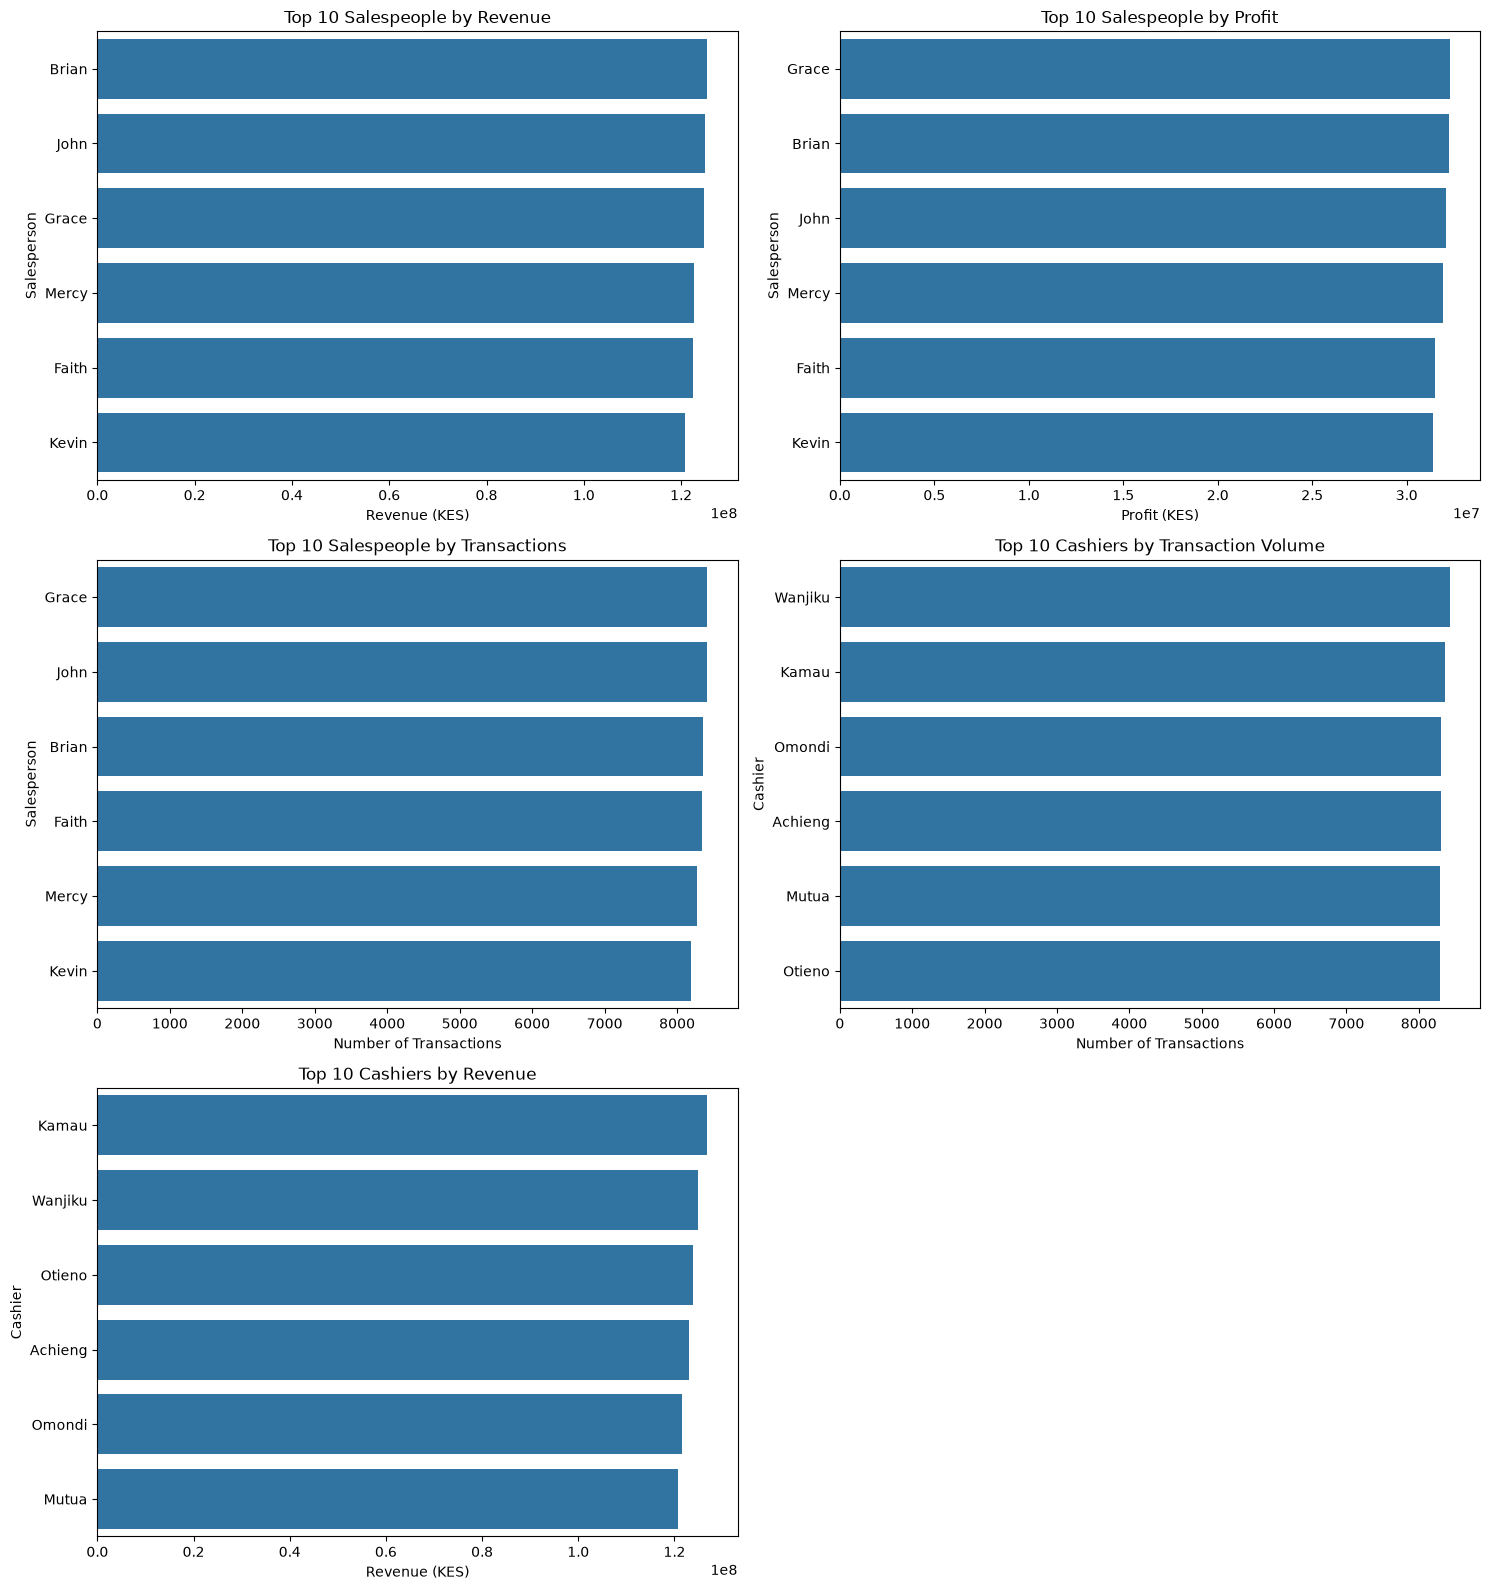

In [27]:
# Section 7: Employee Performance Analysis

# Calculate salesperson performance metrics
salesperson_performance = df.groupby("Salesperson").agg(
    Revenue=("Total_Sales", "sum"),
    Profit=("Profit", "sum"),
    Transactions=("Invoice_ID", "nunique")
).reset_index()

salesperson_performance["Average Transaction Value"] = (
    salesperson_performance["Revenue"] /
    salesperson_performance["Transactions"]
)


# Calculate cashier performance
cashier_performance = df.groupby("Cashier").agg(
    Transactions=("Invoice_ID", "nunique"),
    Revenue=("Total_Sales", "sum"),
    Profit=("Profit", "sum")
).reset_index()

cashier_performance["Average Transaction Value"] = (
    cashier_performance["Revenue"] /
    cashier_performance["Transactions"]
)


# Create a 3-row, 2-column layout
fig, axes = plt.subplots(3, 2, figsize=(15, 16))


# Chart 1: Top 10 Salespeople by Revenue
top_salespeople_revenue = salesperson_performance.sort_values(
    "Revenue", ascending=False
).head(10)

sns.barplot(
    data=top_salespeople_revenue,
    x="Revenue",
    y="Salesperson",
    ax=axes[0, 0]
)

axes[0, 0].set_title("Top 10 Salespeople by Revenue")
axes[0, 0].set_xlabel("Revenue (KES)")
axes[0, 0].set_ylabel("Salesperson")


# Chart 2: Top 10 Salespeople by Profit
top_salespeople_profit = salesperson_performance.sort_values(
    "Profit", ascending=False
).head(10)

sns.barplot(
    data=top_salespeople_profit,
    x="Profit",
    y="Salesperson",
    ax=axes[0, 1]
)

axes[0, 1].set_title("Top 10 Salespeople by Profit")
axes[0, 1].set_xlabel("Profit (KES)")
axes[0, 1].set_ylabel("Salesperson")


# Chart 3: Salesperson Transaction Performance
top_salespeople_transactions = salesperson_performance.sort_values(
    "Transactions", ascending=False
).head(10)

sns.barplot(
    data=top_salespeople_transactions,
    x="Transactions",
    y="Salesperson",
    ax=axes[1, 0]
)

axes[1, 0].set_title("Top 10 Salespeople by Transactions")
axes[1, 0].set_xlabel("Number of Transactions")
axes[1, 0].set_ylabel("Salesperson")


# Chart 4: Top 10 Cashiers by Transaction Volume
top_cashiers = cashier_performance.sort_values(
    "Transactions", ascending=False
).head(10)

sns.barplot(
    data=top_cashiers,
    x="Transactions",
    y="Cashier",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Top 10 Cashiers by Transaction Volume")
axes[1, 1].set_xlabel("Number of Transactions")
axes[1, 1].set_ylabel("Cashier")


# Chart 5: Top 10 Cashiers by Revenue
top_cashiers_revenue = cashier_performance.sort_values(
    "Revenue", ascending=False
).head(10)

sns.barplot(
    data=top_cashiers_revenue,
    x="Revenue",
    y="Cashier",
    ax=axes[2, 0]
)

axes[2, 0].set_title("Top 10 Cashiers by Revenue")
axes[2, 0].set_xlabel("Revenue (KES)")
axes[2, 0].set_ylabel("Cashier")


# Remove unused subplot
axes[2, 1].axis("off")


# Adjust spacing
plt.tight_layout()

plt.show()

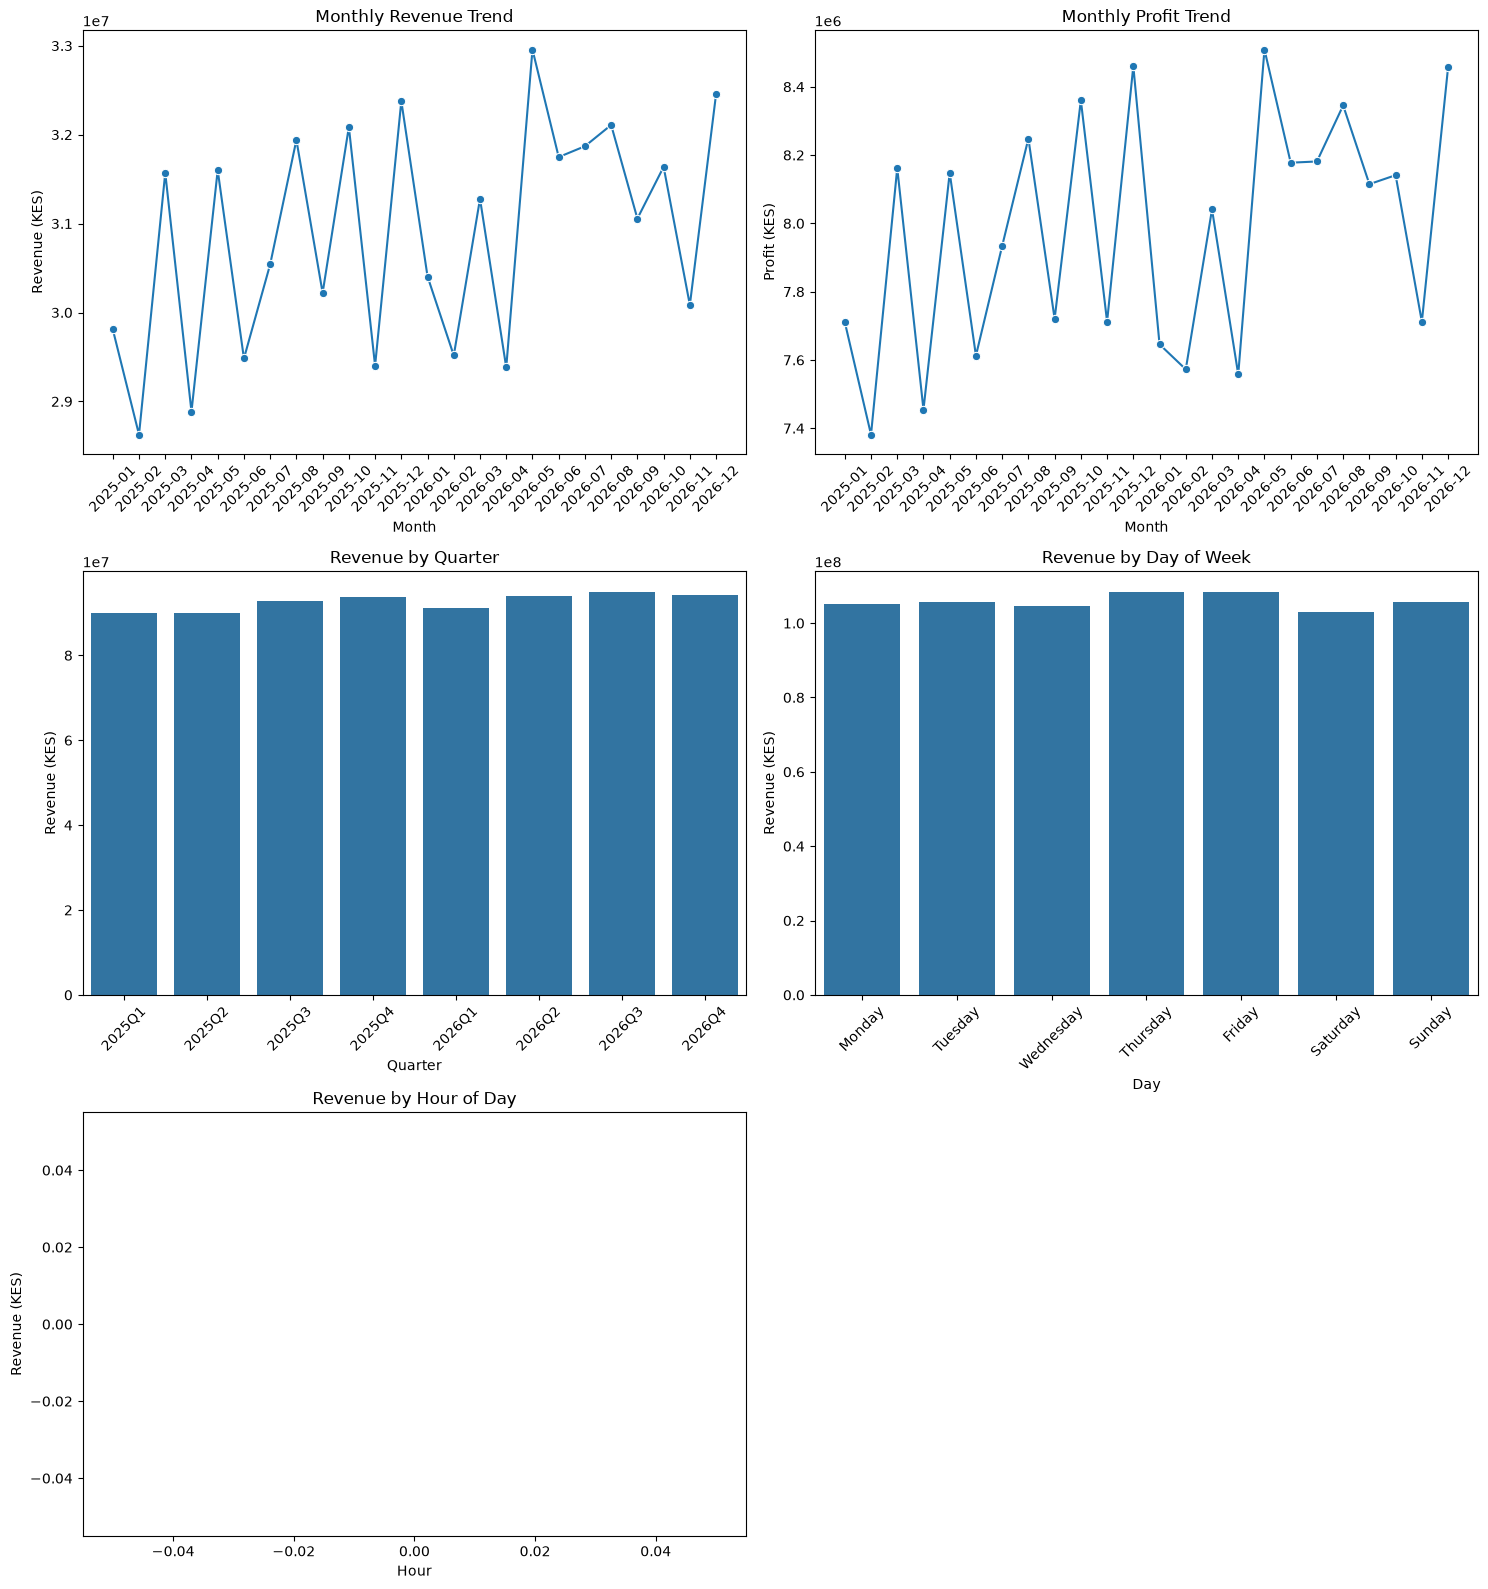

In [29]:
# Section 8: Time-Based Analysis

# Make sure the Date column is in datetime format
df["Date"] = pd.to_datetime(df["Date"])


# Prepare monthly performance data
monthly_performance = df.groupby(
    df["Date"].dt.to_period("M")
).agg(
    Revenue=("Total_Sales", "sum"),
    Profit=("Profit", "sum"),
    Transactions=("Invoice_ID", "nunique")
).reset_index()

monthly_performance["Period"] = (
    monthly_performance["Date"].astype(str)
)

monthly_performance = monthly_performance.sort_values("Date")


# Prepare quarterly performance data
quarterly_performance = df.groupby(
    df["Date"].dt.to_period("Q")
).agg(
    Revenue=("Total_Sales", "sum"),
    Profit=("Profit", "sum"),
    Transactions=("Invoice_ID", "nunique")
).reset_index()

quarterly_performance["Period"] = (
    quarterly_performance["Date"].astype(str)
)

quarterly_performance = quarterly_performance.sort_values("Date")


# Prepare day-of-week performance
df["Day_Name"] = df["Date"].dt.day_name()

day_performance = df.groupby("Day_Name").agg(
    Revenue=("Total_Sales", "sum"),
    Profit=("Profit", "sum"),
    Transactions=("Invoice_ID", "nunique")
).reset_index()

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_performance["Day_Name"] = pd.Categorical(
    day_performance["Day_Name"],
    categories=day_order,
    ordered=True
)

day_performance = day_performance.sort_values("Day_Name")


# Prepare hourly performance
# Convert Time to datetime if it is still stored as text
df["Time"] = pd.to_datetime(
    df["Time"].astype(str),
    format="%H:%M:%S",
    errors="coerce"
)

df["Hour"] = df["Time"].dt.hour

hourly_performance = df.groupby("Hour").agg(
    Revenue=("Total_Sales", "sum"),
    Profit=("Profit", "sum"),
    Transactions=("Invoice_ID", "nunique")
).reset_index()


# Create a 3-row, 2-column layout
fig, axes = plt.subplots(3, 2, figsize=(15, 16))


# Chart 1: Monthly Revenue Trend
sns.lineplot(
    data=monthly_performance,
    x="Period",
    y="Revenue",
    marker="o",
    ax=axes[0, 0]
)

axes[0, 0].set_title("Monthly Revenue Trend")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Revenue (KES)")
axes[0, 0].tick_params(axis="x", rotation=45)


# Chart 2: Monthly Profit Trend
sns.lineplot(
    data=monthly_performance,
    x="Period",
    y="Profit",
    marker="o",
    ax=axes[0, 1]
)

axes[0, 1].set_title("Monthly Profit Trend")
axes[0, 1].set_xlabel("Month")
axes[0, 1].set_ylabel("Profit (KES)")
axes[0, 1].tick_params(axis="x", rotation=45)


# Chart 3: Revenue by Quarter
sns.barplot(
    data=quarterly_performance,
    x="Period",
    y="Revenue",
    ax=axes[1, 0]
)

axes[1, 0].set_title("Revenue by Quarter")
axes[1, 0].set_xlabel("Quarter")
axes[1, 0].set_ylabel("Revenue (KES)")
axes[1, 0].tick_params(axis="x", rotation=45)


# Chart 4: Revenue by Day of Week
sns.barplot(
    data=day_performance,
    x="Day_Name",
    y="Revenue",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Revenue by Day of Week")
axes[1, 1].set_xlabel("Day")
axes[1, 1].set_ylabel("Revenue (KES)")
axes[1, 1].tick_params(axis="x", rotation=45)


# Chart 5: Revenue by Hour
sns.lineplot(
    data=hourly_performance,
    x="Hour",
    y="Revenue",
    marker="o",
    ax=axes[2, 0]
)

axes[2, 0].set_title("Revenue by Hour of Day")
axes[2, 0].set_xlabel("Hour")
axes[2, 0].set_ylabel("Revenue (KES)")


# Remove unused subplot
axes[2, 1].axis("off")


# Adjust spacing
plt.tight_layout()

plt.show()

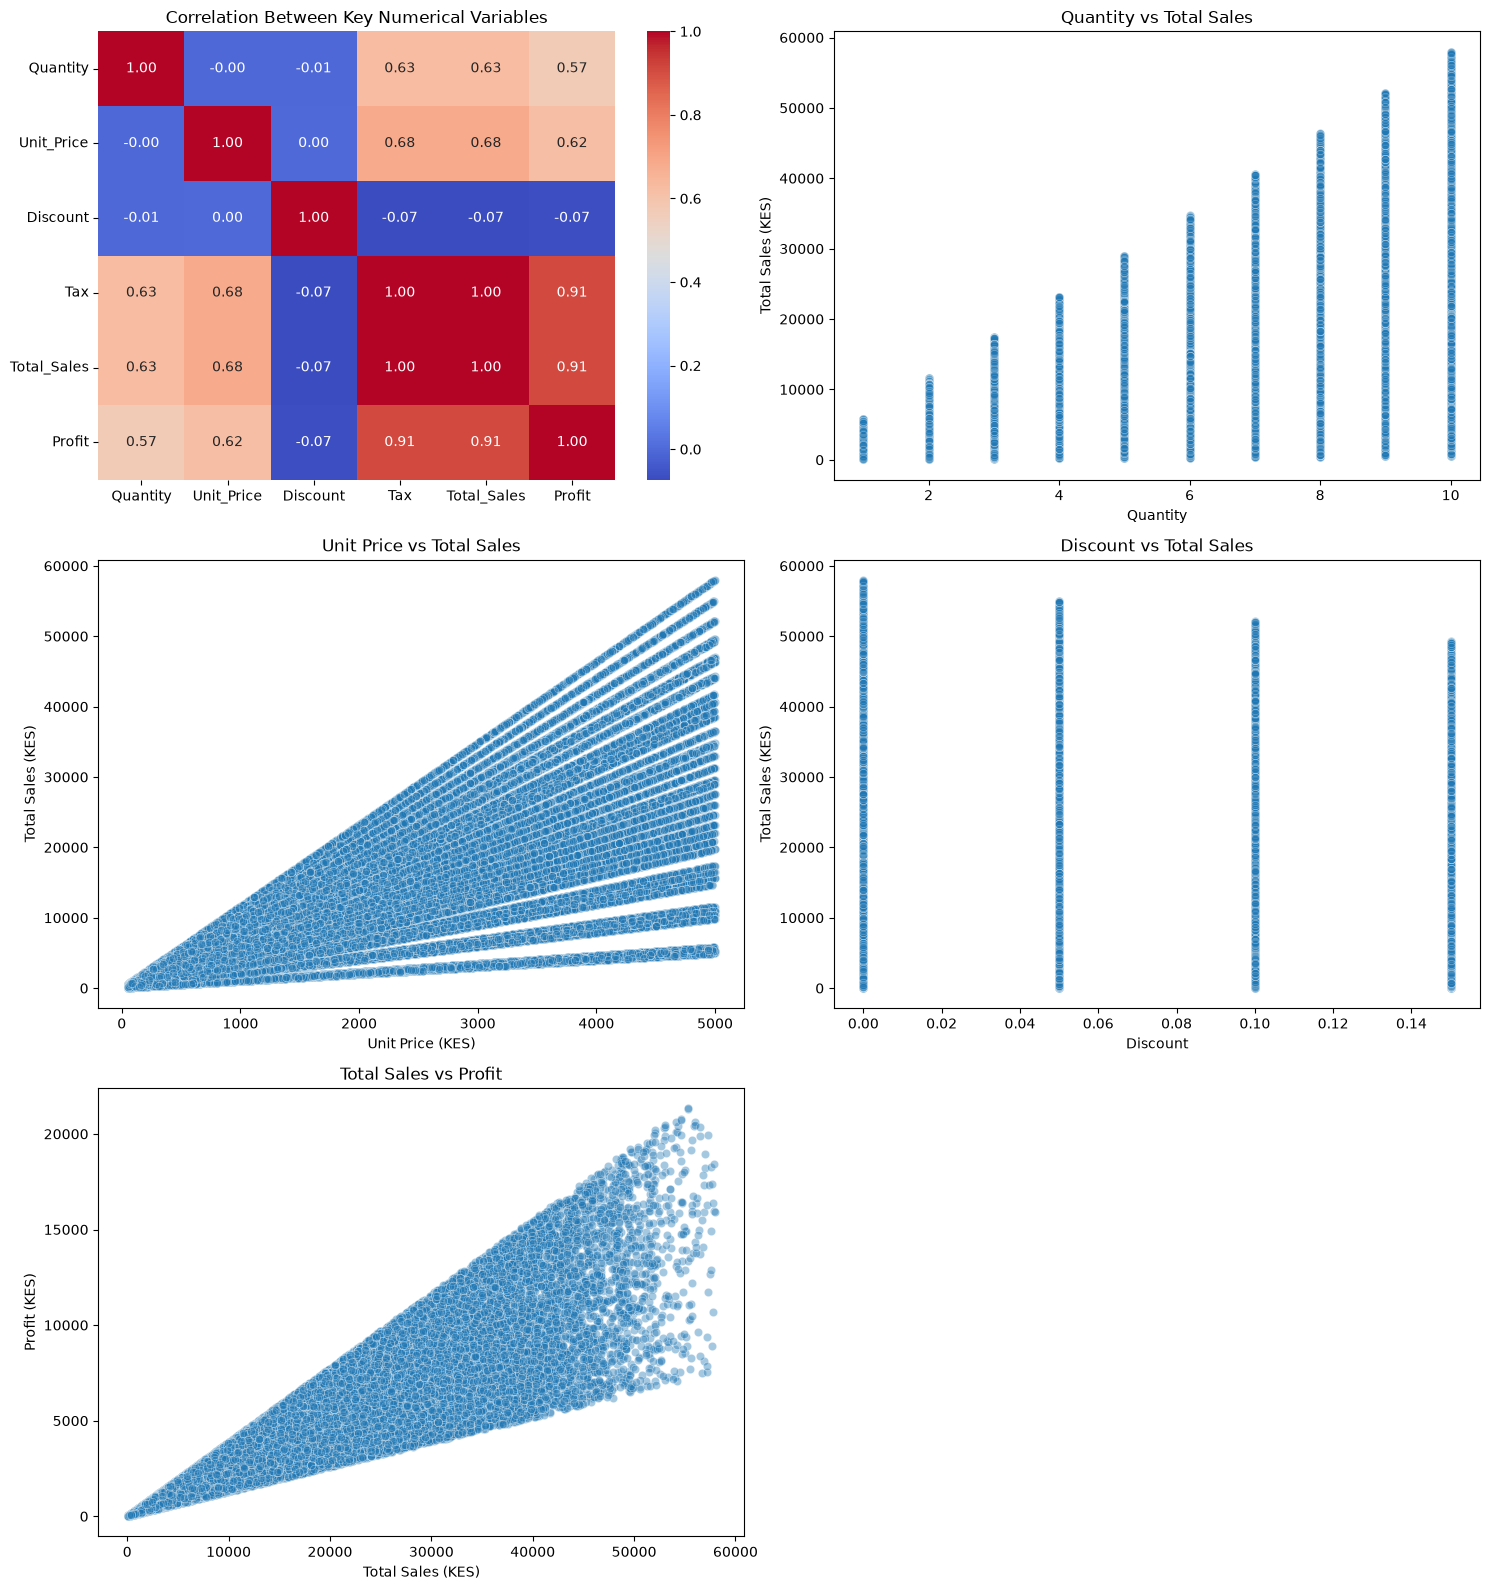

In [30]:
# Section 9: Correlation & Relationship Analysis

# Select key numerical variables for relationship analysis
relationship_data = df[
    [
        "Quantity",
        "Unit_Price",
        "Discount",
        "Tax",
        "Total_Sales",
        "Profit"
    ]
].copy()


# Calculate the correlation matrix
correlation_matrix = relationship_data.corr()


# Create a 3-row, 2-column layout
fig, axes = plt.subplots(3, 2, figsize=(15, 16))


# Chart 1: Correlation Heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    ax=axes[0, 0]
)

axes[0, 0].set_title("Correlation Between Key Numerical Variables")


# Chart 2: Quantity vs Total Sales
sns.scatterplot(
    data=df,
    x="Quantity",
    y="Total_Sales",
    alpha=0.4,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Quantity vs Total Sales")
axes[0, 1].set_xlabel("Quantity")
axes[0, 1].set_ylabel("Total Sales (KES)")


# Chart 3: Unit Price vs Total Sales
sns.scatterplot(
    data=df,
    x="Unit_Price",
    y="Total_Sales",
    alpha=0.4,
    ax=axes[1, 0]
)

axes[1, 0].set_title("Unit Price vs Total Sales")
axes[1, 0].set_xlabel("Unit Price (KES)")
axes[1, 0].set_ylabel("Total Sales (KES)")


# Chart 4: Discount vs Total Sales
sns.scatterplot(
    data=df,
    x="Discount",
    y="Total_Sales",
    alpha=0.4,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Discount vs Total Sales")
axes[1, 1].set_xlabel("Discount")
axes[1, 1].set_ylabel("Total Sales (KES)")


# Chart 5: Total Sales vs Profit
sns.scatterplot(
    data=df,
    x="Total_Sales",
    y="Profit",
    alpha=0.4,
    ax=axes[2, 0]
)

axes[2, 0].set_title("Total Sales vs Profit")
axes[2, 0].set_xlabel("Total Sales (KES)")
axes[2, 0].set_ylabel("Profit (KES)")


# Remove unused subplot
axes[2, 1].axis("off")


# Adjust spacing
plt.tight_layout()

plt.show()

In [32]:
# Section 10: Key Visual Insights

# Identify the strongest business performers from the analysis

highest_revenue_product = product_performance.loc[
    product_performance["Revenue"].idxmax(), "Product"
]

highest_profit_product = product_performance.loc[
    product_performance["Profit"].idxmax(), "Product"
]

highest_margin_product = product_performance.loc[
    product_performance["Profit Margin (%)"].idxmax(), "Product"
]

highest_revenue_customer_type = customer_performance.loc[
    customer_performance["Revenue"].idxmax(), "Customer_Type"
]

highest_revenue_payment_method = payment_performance.loc[
    payment_performance["Revenue"].idxmax(), "Payment_Method"
]

highest_revenue_salesperson = salesperson_performance.loc[
    salesperson_performance["Revenue"].idxmax(), "Salesperson"
]

highest_revenue_branch = branch_performance.loc[
    branch_performance["Revenue"].idxmax(), "Branch"
]

highest_profit_city = city_performance.loc[
    city_performance["Profit"].idxmax(), "City"
]

highest_revenue_month = monthly_performance.loc[
    monthly_performance["Revenue"].idxmax(), "Period"
]

highest_revenue_day = day_performance.loc[
    day_performance["Revenue"].idxmax(), "Day_Name"
]


# Identify the highest revenue hour only if hourly data is available

if not hourly_performance.empty and hourly_performance["Revenue"].notna().any():
    highest_revenue_hour = hourly_performance.loc[
        hourly_performance["Revenue"].idxmax(), "Hour"
    ]
else:
    highest_revenue_hour = "Not available"


# Display the key visual insights

print("KEY VISUAL INSIGHTS")
print("=" * 50)

print(f"Highest Revenue Branch: {highest_revenue_branch}")
print(f"Highest Profit City: {highest_profit_city}")
print(f"Highest Revenue Product: {highest_revenue_product}")
print(f"Highest Profit Product: {highest_profit_product}")
print(f"Highest Profit Margin Product: {highest_margin_product}")
print(f"Top Customer Type by Revenue: {highest_revenue_customer_type}")
print(f"Top Payment Method by Revenue: {highest_revenue_payment_method}")
print(f"Top Salesperson by Revenue: {highest_revenue_salesperson}")
print(f"Highest Revenue Month: {highest_revenue_month}")
print(f"Highest Revenue Day: {highest_revenue_day}")
print(f"Highest Revenue Hour: {highest_revenue_hour}")

KEY VISUAL INSIGHTS
Highest Revenue Branch: Nakuru
Highest Profit City: Nairobi
Highest Revenue Product: Bucket
Highest Profit Product: USB Flash
Highest Profit Margin Product: Book
Top Customer Type by Revenue: Member
Top Payment Method by Revenue: Cash
Top Salesperson by Revenue: Brian
Highest Revenue Month: 2026-05
Highest Revenue Day: Thursday
Highest Revenue Hour: Not available
